# Module project: build a fuel-use predictor

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-1-mpg-predictor.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-1-foundations/files/project-1-mpg-predictor.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/mpg-predictor` folder in the course files, to check your work.
- **Data**: Auto MPG (UCI Machine Learning Repository). Source: [https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv](https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv) · about: [https://archive.ics.uci.edu/dataset/9/auto+mpg](https://archive.ics.uci.edu/dataset/9/auto+mpg) · licence: CC BY 4.0. `data.py` downloads it the first time you run it and keeps it in `data/`: `auto-mpg.csv`, 12 KB.

In [ ]:
%pip install -q torch pandas matplotlib

In this project you turn chapter 1 into a small, real piece of software: a PyTorch program that predicts how much fuel a
car uses from its horsepower, and chooses its own complexity honestly. At the end you'll have a GitHub repository with
code, a results table, a plot and a README, ready to link from your CV.

You'll type every file yourself. This lesson comes with a notebook (attached above) that builds and runs the whole project, and the finished
reference code is in the course files under `projects/mpg-predictor`. Look at them only when you're stuck or to check
your work: the point is that you can build it yourself.





## What you'll build

```mermaid
flowchart LR
    A[Auto MPG data<br/>398 real cars] --> B[data.py<br/>clean + split + standardize]
    B --> C[model.py<br/>polynomial of degree M]
    C --> D[train.py<br/>minimize error + penalty]
    D --> E[select_model.py<br/>5-fold cross-validation]
    E --> F[test set<br/>used once]
    E --> G[predict.py<br/>new cars]
```

The data set is the classic Auto MPG table: 398 cars from the 1970s and early 80s, with their fuel use in miles per
gallon (mpg) and their horsepower. It's chapter 1's curve-fitting problem, but with real noise instead of a sine wave.

## Set up the project

On your own computer, make a folder and a virtual environment, and install the three libraries:

```bash
mkdir mpg-predictor && cd mpg-predictor
python -m venv .venv
source .venv/bin/activate          # on Windows: .venv\Scripts\activate
pip install torch pandas matplotlib
git init
```

Here is the layout you'll end up with:

```text
mpg-predictor/
    .gitignore
    README.md
    data.py
    model.py
    predict.py
    requirements.txt
    select_model.py
    train.py
```

Create `requirements.txt` (so others can install what you used) and `.gitignore` (so the downloaded data and the
virtual environment stay out of git; add `.venv/` to it too):

In [ ]:
%%writefile requirements.txt
torch
pandas
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/

Writing .gitignore


## Step 1: load and split the data

Three decisions matter here, and each comes from the chapter:

- **Three sets.** 60% of the cars for training, 20% for validation, 20% for a test set that you look at only at the very end.
- **A fixed seed**, so your split (and your numbers) are the same every time you run it.
- **Standardize with the training mean and spread only.** If the test cars influenced the scaling, information about
  them would leak into training.

In [ ]:
%%writefile data.py
"""Download the Auto MPG data and split it into train / validation / test sets."""
from pathlib import Path
import pandas as pd
import torch

URL = "https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv"
CACHE = Path("data/auto-mpg.csv")


def load_table():
    if not CACHE.exists():
        CACHE.parent.mkdir(exist_ok=True)
        pd.read_csv(URL).to_csv(CACHE, index=False)
    return pd.read_csv(CACHE).dropna()          # 6 cars have no horsepower value


def load_splits(feature="horsepower", seed=0):
    """Return (x, t) tensors for train, val and test. x is standardized with the TRAIN mean and std only."""
    table = load_table()
    x = torch.tensor(table[feature].values, dtype=torch.float32)
    t = torch.tensor(table["mpg"].values, dtype=torch.float32)
    order = torch.randperm(len(x), generator=torch.Generator().manual_seed(seed))
    n_train, n_val = int(0.6 * len(x)), int(0.2 * len(x))
    parts = order[:n_train], order[n_train:n_train + n_val], order[n_train + n_val:]
    mean, std = x[parts[0]].mean(), x[parts[0]].std()
    scale = lambda v: (v - mean) / std
    return {name: (scale(x[idx]), t[idx]) for name, idx in zip(["train", "val", "test"], parts)}, (mean, std)


if __name__ == "__main__":
    splits, _ = load_splits()
    for name, (x, t) in splits.items():
        print(f"{name:5s}: {len(x):3d} cars, mean mpg {t.mean():.1f}")

Writing data.py


Run it to check the split:

In [ ]:
!python data.py

train: 237 cars, mean mpg 23.5
val  :  79 cars, mean mpg 22.6
test :  80 cars, mean mpg 24.5


## Step 2: the model

The model is equation 1.1 of the book: `y(x, w) = w0 + w1 x + ... + wM x^M`. In PyTorch, that's a linear layer applied to
the features `x, x², ..., x^M`. The layer's bias plays the role of `w0`.

In [ ]:
%%writefile model.py
"""A polynomial regression model: y(x, w) = w0 + w1 x + ... + wM x^M  (Bishop, section 1.2)."""
import torch
from torch import nn


class Polynomial(nn.Module):
    def __init__(self, degree):
        super().__init__()
        self.degree = degree
        self.linear = nn.Linear(degree, 1)        # the bias is w0, the weights are w1..wM

    def features(self, x):
        return torch.stack([x ** j for j in range(1, self.degree + 1)], dim=1)

    def forward(self, x):
        return self.linear(self.features(x)).squeeze(1)

Writing model.py


## Step 3: train one model

`fit` minimizes the regularized error of equation 1.4: half the sum of squared errors, plus `λ/2` times the squared
weights. We leave the bias out of the penalty, as the book recommends, so the penalty doesn't pull every prediction
towards zero mpg.

The data set is small, so we use L-BFGS, an optimizer that uses the whole data set at every step and converges in a few
dozen iterations. (Chapter 7 covers the stochastic optimizers you'll use for big data sets.)

In [ ]:
%%writefile train.py
"""Fit one polynomial by minimizing the regularized sum-of-squares error (Bishop, equation 1.4)."""
import argparse
import torch
from data import load_splits
from model import Polynomial


def fit(x, t, degree, lam=0.0, steps=500):
    torch.manual_seed(0)
    model = Polynomial(degree)
    opt = torch.optim.LBFGS(model.parameters(), lr=1, max_iter=steps, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        error = 0.5 * ((model(x) - t) ** 2).sum()
        penalty = 0.5 * lam * (model.linear.weight ** 2).sum()   # the bias is not penalized
        loss = error + penalty
        loss.backward()
        return loss

    opt.step(closure)
    return model


def rmse(model, x, t):
    with torch.no_grad():
        return ((model(x) - t) ** 2).mean().sqrt().item()


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--degree", type=int, default=2)
    ap.add_argument("--lam", type=float, default=0.0)
    args = ap.parse_args()
    splits, _ = load_splits()
    model = fit(*splits["train"], args.degree, args.lam)
    for name in ["train", "val"]:
        print(f"degree {args.degree}, lambda {args.lam:g}: {name} RMSE {rmse(model, *splits[name]):.2f} mpg")

Writing train.py


Try three degrees:

In [ ]:
!python train.py --degree 1

degree 1, lambda 0: train RMSE 4.82 mpg
degree 1, lambda 0: val RMSE 4.76 mpg


In [ ]:
!python train.py --degree 2

degree 2, lambda 0: train RMSE 4.09 mpg
degree 2, lambda 0: val RMSE 4.23 mpg


In [ ]:
!python train.py --degree 9

degree 9, lambda 0: train RMSE 3.99 mpg
degree 9, lambda 0: val RMSE 4.23 mpg


The straight line is clearly too simple. But notice that degree 9 doesn't over-fit badly here: with 237 cars, there's
enough data to keep 10 parameters in check. Section 1.2.4 (figure 1.8) said exactly this: the larger the data set, the more
complex the model it can support.

## Step 4: choose the model honestly

Now the heart of the project. For each degree from 1 to 8 and each λ, run 5-fold cross-validation (section 1.2.6) on the
training and validation cars together. Then choose one model and measure it **once** on the test set.

In [ ]:
%%writefile select_model.py
"""Choose the degree M and the penalty lambda by 5-fold cross-validation (Bishop, section 1.2.6),
then measure the chosen model ONCE on the test set."""
import argparse
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load_splits
from train import fit, rmse

DEGREES = range(1, 9)
LAMBDAS = [0.0, 0.1, 10.0]


def cross_val(x, t, degree, lam, folds=5):
    idx = torch.arange(len(x))
    errors = []
    for k in range(folds):
        held = idx % folds == k
        model = fit(x[~held], t[~held], degree, lam)
        errors.append(rmse(model, x[held], t[held]))
    return sum(errors) / folds


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--n-train", type=int, default=None, help="use only this many cars for training")
    args = ap.parse_args()
    splits, (mean, std) = load_splits()
    x = torch.cat([splits["train"][0], splits["val"][0]])
    t = torch.cat([splits["train"][1], splits["val"][1]])
    if args.n_train:
        x, t = x[:args.n_train], t[:args.n_train]
    print(f"choosing with {len(x)} cars\n")
    print("degree " + "".join(f"  lambda={lam:<5g}" for lam in LAMBDAS))
    scores = {}
    for degree in DEGREES:
        row = [cross_val(x, t, degree, lam) for lam in LAMBDAS]
        scores.update({(degree, lam): s for lam, s in zip(LAMBDAS, row)})
        print(f"{degree:6d} " + "".join(f"  {s:12.2f}" for s in row))

    best = min(scores, key=scores.get)
    # Several models score almost the same. Prefer the simplest one within 1% of the best:
    # lowest degree first, then the strongest penalty.
    near = [k for k in scores if scores[k] <= 1.01 * scores[best]]
    degree, lam = min(near, key=lambda k: (k[0], -k[1]))
    model = fit(x, t, degree, lam)
    x_test, t_test = splits["test"]
    print(f"\nbest score: degree {best[0]}, lambda {best[1]:g} (cross-validation RMSE {scores[best]:.2f})")
    print(f"chosen (simplest within 1%): degree {degree}, lambda {lam:g} (cross-validation RMSE {scores[degree, lam]:.2f})")
    print(f"test RMSE of the chosen model: {rmse(model, x_test, t_test):.2f} mpg")
    print(f"test RMSE of 'always guess the average': {((t_test - t.mean()) ** 2).mean().sqrt():.2f} mpg")

    Path("outputs").mkdir(exist_ok=True)
    grid = torch.linspace(x.min(), x.max(), 200)
    with torch.no_grad():
        plt.scatter(x * std + mean, t, s=8, alpha=0.5, label="cars used for fitting")
        plt.plot(grid * std + mean, model(grid), "r", label=f"chosen model (M={degree})")
    plt.xlabel("horsepower"); plt.ylabel("miles per gallon"); plt.legend()
    name = f"outputs/fit_n{len(x)}.png"
    plt.savefig(name, dpi=120)
    print("saved", name)

Writing select_model.py


In [ ]:
!python select_model.py

choosing with 316 cars

degree   lambda=0      lambda=0.1    lambda=10   
     1           4.81          4.81          4.82
     2           4.13          4.13          4.16
     3           4.13          4.13          4.16
     4           4.14          4.14          4.20
     5           4.11          4.11          4.19
     6           4.13          4.13          4.17
     7           4.16          4.15          4.11
     8           4.18          4.18          4.13

best score: degree 5, lambda 0.1 (cross-validation RMSE 4.11)
chosen (simplest within 1%): degree 2, lambda 0.1 (cross-validation RMSE 4.13)
test RMSE of the chosen model: 5.28 mpg
test RMSE of 'always guess the average': 8.02 mpg
saved outputs/fit_n316.png


Read the table before you read the choice. Degrees 2 to 8 all score within a few hundredths of each other: the extra
flexibility buys almost nothing. The single best score is degree 5, but its curve bends back upwards for the most powerful
cars, which makes no physical sense. That's why the script prefers the **simplest model within 1% of the best**. This is a
common rule in practice: when the data can't tell models apart, choose the one that assumes less.

Also look at the test error: 5.28 mpg, higher than the cross-validation error of 4.13. Your test set of 80 cars just
happens to contain some harder cars. That's normal, and it's why you report the test number rather than the
cross-validation one: it's the only one that played no part in any choice.

Now repeat with only 20 cars:

In [ ]:
!python select_model.py --n-train 20

choosing with 20 cars

degree   lambda=0      lambda=0.1    lambda=10   
     1           4.35          4.34          4.56
     2           5.36          5.31          4.72
     3           5.87          5.22          8.25
     4          41.80         33.89         14.90
     5          40.63         21.27         28.32
     6         168.33        129.92         71.20
     7        2017.08         87.76         92.50
     8       18906.85        474.62        290.94

best score: degree 1, lambda 0.1 (cross-validation RMSE 4.34)
chosen (simplest within 1%): degree 1, lambda 0.1 (cross-validation RMSE 4.34)
test RMSE of the chosen model: 5.56 mpg
test RMSE of 'always guess the average': 7.94 mpg
saved outputs/fit_n20.png


This is the over-fitting of figure 1.6, on real data. With 20 cars, degree 8 without a penalty reaches a cross-validation error
of thousands of mpg: it threads through the 16 training cars of each fold and goes wild between them. The penalty
(λ = 10) cuts this hugely, and cross-validation correctly falls back to a straight line.

Here is the chosen model on the full data (your own `outputs/fit_n316.png`):

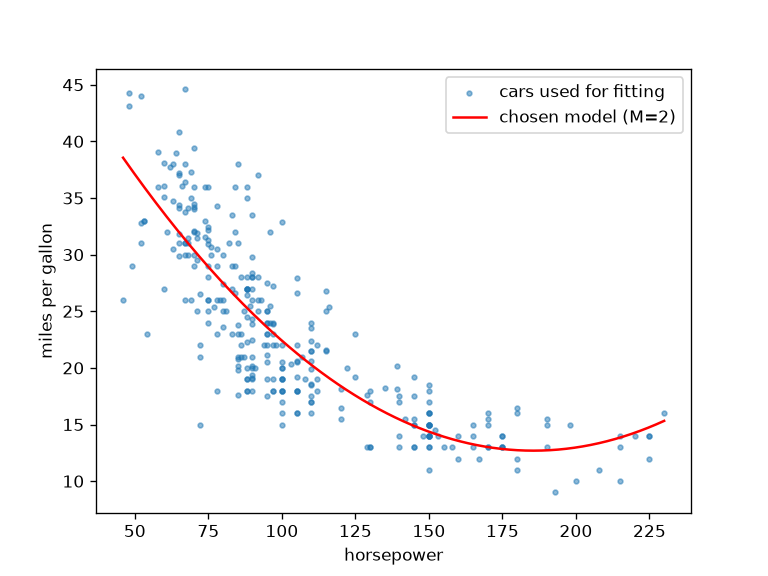

In [ ]:
from IPython.display import Image
Image('outputs/fit_n316.png')

Open `outputs/fit_n20.png` to see the 20-car fit.

## Step 5: use it

A model is only useful if someone can ask it a question:

In [ ]:
%%writefile predict.py
"""Predict the fuel use of a new car from its horsepower, with the chosen model (degree 2, lambda 0.1)."""
import argparse
import torch
from data import load_splits
from train import fit

ap = argparse.ArgumentParser()
ap.add_argument("horsepower", type=float, nargs="+")
args = ap.parse_args()

splits, (mean, std) = load_splits()
x = torch.cat([splits["train"][0], splits["val"][0]])
t = torch.cat([splits["train"][1], splits["val"][1]])
model = fit(x, t, degree=2, lam=0.1)
with torch.no_grad():
    for hp in args.horsepower:
        mpg = model(torch.tensor([(hp - mean) / std])).item()
        print(f"{hp:5.0f} hp -> {mpg:4.1f} mpg  ({235.2 / mpg:4.1f} litres per 100 km)")

Writing predict.py


In [ ]:
!python predict.py 70 150

   70 hp -> 30.4 mpg  ( 7.7 litres per 100 km)
  150 hp -> 14.4 mpg  (16.4 litres per 100 km)


## Step 6: write the README and publish

A README is what a recruiter or an interviewer actually reads. Keep it short: what it does, the results, how to run it,
what you learned. Here's the reference one; write yours in your own words and with your own numbers:

In [ ]:
%%writefile README.md
# Fuel-use predictor

Predicts a car's fuel use (miles per gallon) from its horsepower with polynomial regression in PyTorch,
and chooses the model's complexity honestly with 5-fold cross-validation.

![fit](outputs/fit_n316.png)

## Results

| model | test RMSE (mpg) |
|---|---|
| always guess the average | 8.02 |
| polynomial, degree 2, lambda 0.1 (chosen by cross-validation) | 5.28 |

With only 20 training cars, a degree-8 polynomial reaches a cross-validation error of thousands of mpg:
a clear case of over-fitting, fixed by choosing a lower degree or a larger penalty.

## Run it

```bash
pip install -r requirements.txt
python select_model.py            # choose the degree and lambda, report the test error
python select_model.py --n-train 20
python predict.py 70 150
```

## What I learned

- Training error always prefers the most flexible model; only held-out data can choose.
- Cross-validation uses every car for both fitting and checking, which matters when data is scarce.
- When several models score the same, the simplest one is the safer choice.

Based on chapter 1 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


Then create an empty repository on GitHub (without a README, since you already have one) and push:

```bash
git add .
git commit -m "Fuel-use predictor with cross-validated model selection"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/mpg-predictor.git
git push -u origin main
```

## Make it yours

Don't stop at a copy of the reference. Pick at least one of these, and add the result to your README:

- **More inputs.** Use weight, model year and cylinders too. Section 4.1 shows that nothing changes in the method: the
  features become a matrix. How low can the test error go?
- **Litres per 100 km.** Predict `235.2 / mpg` instead of mpg. Is the relationship with horsepower simpler in those units?
- **A learning curve.** Plot the test error against the number of training cars (20, 40, 80, 160, 316). Where does more
  data stop helping?
- **Your own data.** Any table with one number to predict works: house prices, exam scores, your phone's battery level
  over time.

## On your CV

Under a "Projects" heading, one or two lines with a link:

> **Fuel-use predictor** (PyTorch): polynomial regression on 392 real cars with 5-fold cross-validation over model degree
> and L2 penalty; reduced test error from 8.0 to 5.3 mpg against a mean baseline, and showed over-fitting on small
> samples. github.com/YOUR-USERNAME/mpg-predictor

Use your own numbers, and mention what **you** added in "Make it yours". That's the part an interviewer will ask about.

## Check yourself

Before you call it done:

- [ ] `python select_model.py` runs from a fresh clone after `pip install -r requirements.txt`.
- [ ] The test set is used only once, after the choice.
- [ ] Your README has a results table and at least one plot.
- [ ] You can explain, without notes, why the training error can't be used to choose the degree.